# Wizualizacja i porównanie pomiędzy różnymi modelami

In [9]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_from_disk
from model.training_orchiestration import ModelRun


MODEL_CATALOG = PROJECT_ROOT / "model" / "model_catalog"
DATA_PATH = PROJECT_ROOT / "data"

In [10]:
def load_run_summaries(catalog_dir):
    rows = []
    histories = {}

    for run_dir in sorted(Path(catalog_dir).iterdir()):
        if not run_dir.is_dir():
            continue

        history_path = run_dir / "training_history.json"
        config_path = run_dir / "config.json"

        if not history_path.exists():
            continue

        with open(history_path, "r", encoding="utf-8") as f:
            history = json.load(f)

        if len(history) == 0:
            continue

        histories[run_dir.name] = history

        config = {}
        if config_path.exists():
            with open(config_path, "r", encoding="utf-8") as f:
                config = json.load(f)

        best = min(history, key=lambda r: r.get("val_loss", float("inf")))
        last = history[-1]

        rows.append(
            {
                "run": run_dir.name,
                "mode": config.get("mode"),
                "epochs": len(history),
                "best_epoch": best["epoch"],
                "best_val_loss": best.get("val_loss"),
                "best_val_acc": best.get("val_acc"),
                "best_val_f1_macro": best.get("val_f1_macro"),
                "best_val_f1_weighted": best.get("val_f1_weighted"),
                "last_val_loss": last.get("val_loss"),
                "last_val_acc": last.get("val_acc"),
            }
        )

    summary = pd.DataFrame(rows)
    return summary, histories


summary, histories = load_run_summaries(MODEL_CATALOG)

summary

,run,mode,epochs,best_epoch,best_val_loss,best_val_acc,best_val_f1_macro,best_val_f1_weighted,last_val_loss,last_val_acc
0,20261120_182042_TrainingMode.DEBUG_279407,debug,10,8,2.131986,0.487227,0.449669,0.474189,2.222168,0.518129


#### Podsumowanie treningów

In [11]:
if not summary.empty:
    display(
        summary.sort_values("best_val_f1_macro", ascending=False)
    )

,run,mode,epochs,best_epoch,best_val_loss,best_val_acc,best_val_f1_macro,best_val_f1_weighted,last_val_loss,last_val_acc
0,20261120_182042_TrainingMode.DEBUG_279407,debug,10,8,2.131986,0.487227,0.449669,0.474189,2.222168,0.518129


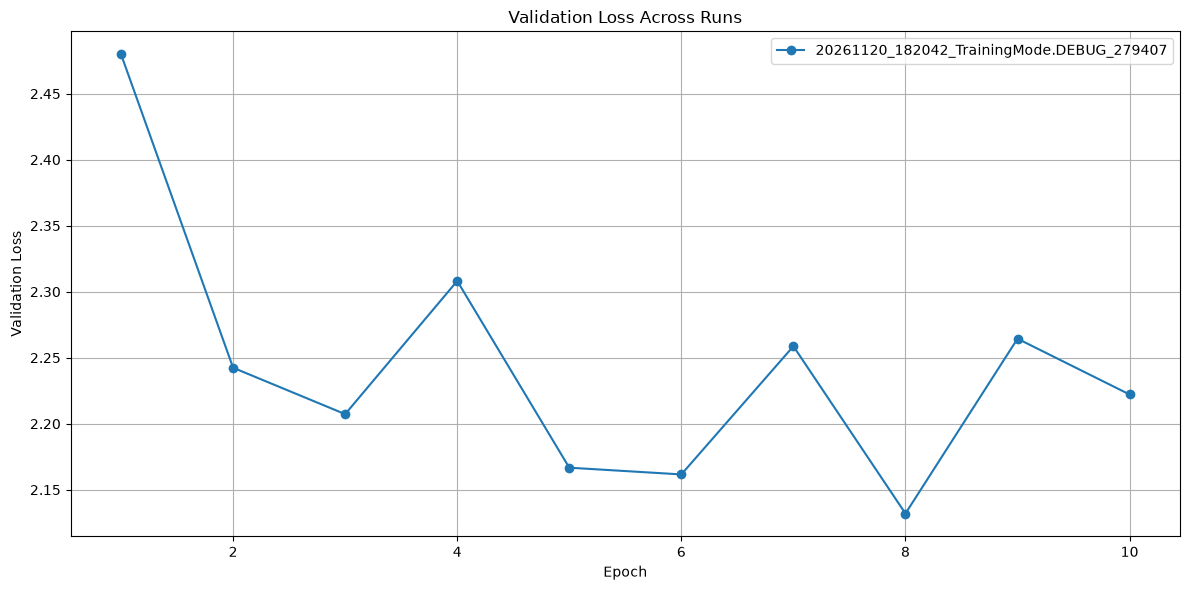

In [12]:
plt.figure(figsize=(12, 6))

for run_name, history in histories.items():
    df = pd.DataFrame(history)

    plt.plot(
        df["epoch"],
        df["val_loss"],
        marker="o",
        label=run_name,
    )

plt.title("Validation Loss Across Runs")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

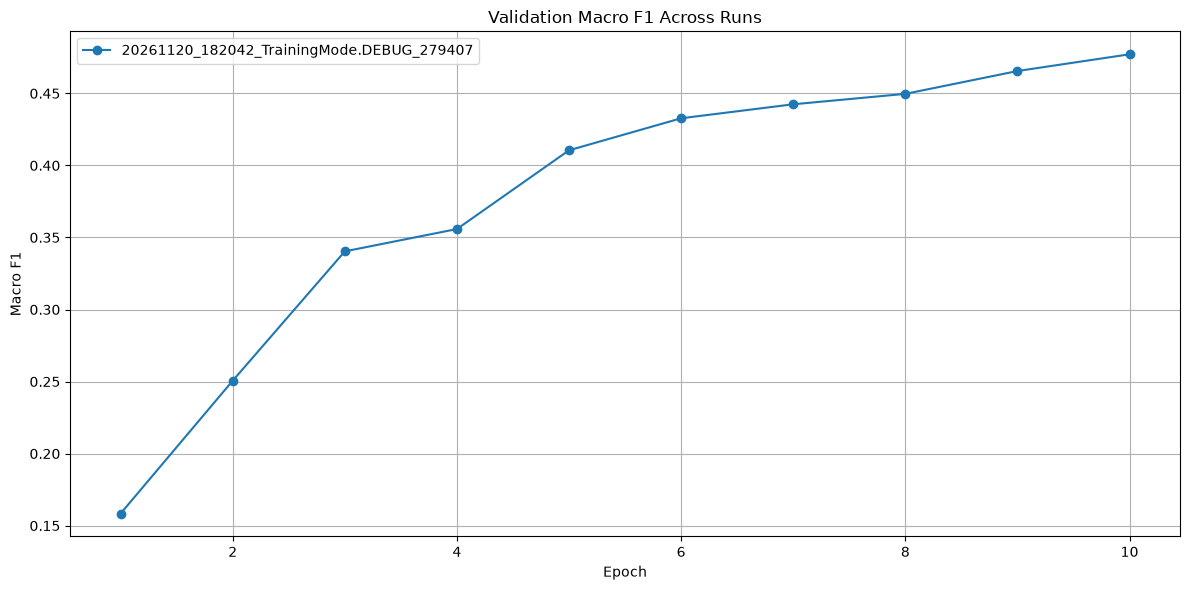

In [13]:
plt.figure(figsize=(12, 6))

for run_name, history in histories.items():
    df = pd.DataFrame(history)

    if "val_f1_macro" in df.columns:
        plt.plot(
            df["epoch"],
            df["val_f1_macro"],
            marker="o",
            label=run_name,
        )

plt.title("Validation Macro F1 Across Runs")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()